<a href="https://colab.research.google.com/github/Siva-p-11/ML-assiments/blob/main/BAYESIAN_LOGISTIC_REGRESSIONipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# Q4: BAYESIAN LOGISTIC REGRESSION WITH LAPLACE
#     vs RBF KERNEL SVM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=4, suppress=True)

# ------------------------------------------------------------
# Student-specific seed
# Last two digits of roll number = 57
# ------------------------------------------------------------

SEED = 57

np.random.seed(SEED)

print("Student seed:", SEED)

Student seed: 57


In [ ]:
# ============================================================
# CELL 2: STUDENT-SPECIFIC NONLINEAR DATASET
# ============================================================

rng = np.random.default_rng(SEED)

# Student-specific noise
noise = rng.uniform(0.12, 0.22)

# Student-specific rotation
angle = rng.uniform(10, 45)

theta = np.radians(angle)

# Generate nonlinear two-class moon dataset
X, y = make_moons(
    n_samples=300,
    noise=noise,
    random_state=SEED
)

# Rotation matrix
R = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

# Apply rotation
X = X @ R.T

print("Student seed:", SEED)
print("Student-specific noise:", round(noise, 4))
print("Student-specific rotation:", round(angle, 2), "degrees")
print("Dataset shape:", X.shape)
print("Class 0 samples:", np.sum(y == 0))
print("Class 1 samples:", np.sum(y == 1))

Student seed: 57
Student-specific noise: 0.1884
Student-specific rotation: 26.39 degrees
Dataset shape: (300, 2)
Class 0 samples: 150
Class 1 samples: 150


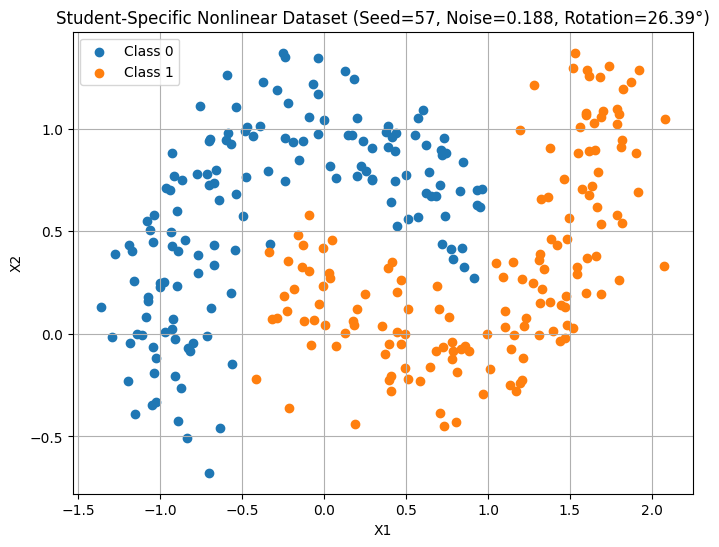

In [ ]:
# ============================================================
# CELL 3: DATASET VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1"
)

plt.xlabel("X1")
plt.ylabel("X2")

plt.title(
    f"Student-Specific Nonlinear Dataset "
    f"(Seed={SEED}, Noise={noise:.3f}, Rotation={angle:.2f}°)"
)

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 4: TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=SEED,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 225
Testing samples: 75


In [ ]:
# ============================================================
# CELL 5: NONLINEAR BASIS-FUNCTION EXPANSION
# ============================================================

def basis_function(X):

    x1 = X[:, 0]
    x2 = X[:, 1]

    Phi = np.column_stack([
        np.ones(len(X)),
        x1,
        x2,
        x1**2,
        x1 * x2,
        x2**2,
        x1**3,
        x1**2 * x2,
        x1 * x2**2,
        x2**3
    ])

    return Phi


Phi_train = basis_function(X_train)
Phi_test = basis_function(X_test)

print("Original feature dimension:", X_train.shape[1])
print("Basis-function dimension:", Phi_train.shape[1])

Original feature dimension: 2
Basis-function dimension: 10


In [ ]:
# ============================================================
# CELL 6:
# BAYESIAN LOGISTIC REGRESSION
# USING LAPLACE APPROXIMATION
# ============================================================

def sigmoid(z):

    z = np.clip(z, -50, 50)

    return 1.0 / (1.0 + np.exp(-z))


def bayesian_logistic_laplace(
    Phi,
    y,
    alpha=1.0,
    max_iter=100,
    tol=1e-6
):

    n_features = Phi.shape[1]

    # Initial weights
    w = np.zeros(n_features)

    # Newton-Raphson optimization
    for iteration in range(max_iter):

        # Predicted probabilities
        p = sigmoid(Phi @ w)

        # Diagonal of R matrix
        R = p * (1 - p)

        # Gradient of negative log posterior
        gradient = (
            Phi.T @ (p - y)
            + alpha * w
        )

        # Hessian
        H = (
            Phi.T @ (R[:, None] * Phi)
            + alpha * np.eye(n_features)
        )

        # Newton-Raphson step
        step = np.linalg.solve(
            H,
            gradient
        )

        w_new = w - step

        # Convergence check
        if np.linalg.norm(w_new - w) < tol:

            w = w_new

            break

        w = w_new

    # MAP estimate
    w_map = w

    # Hessian evaluated at MAP
    p_map = sigmoid(Phi @ w_map)

    R_map = p_map * (1 - p_map)

    H_map = (
        Phi.T @ (R_map[:, None] * Phi)
        + alpha * np.eye(n_features)
    )

    # Laplace covariance
    covariance = np.linalg.inv(H_map)

    return (
        w_map,
        covariance,
        iteration + 1
    )


# ------------------------------------------------------------
# Prior precision
# ------------------------------------------------------------

alpha = 1.0


# ------------------------------------------------------------
# Fit model
# ------------------------------------------------------------

w_map, covariance, iterations = (
    bayesian_logistic_laplace(
        Phi_train,
        y_train,
        alpha=alpha
    )
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("Bayesian Logistic Regression")
print("=" * 65)

print("Prior precision alpha:", alpha)

print(
    "Number of basis functions:",
    Phi_train.shape[1]
)

print(
    "Newton-Raphson iterations:",
    iterations
)

print("\nMAP weights:")
print(w_map)

print("\nPosterior covariance:")
print(covariance)

Bayesian Logistic Regression
Prior precision alpha: 1.0
Number of basis functions: 10
Newton-Raphson iterations: 8

MAP weights:
[ 1.0532  0.6225 -2.2406 -1.5291 -1.0848 -1.6237  2.6831  0.4209  0.8713
 -0.5233]

Posterior covariance:
[[ 0.1199 -0.0173 -0.0698 -0.1139  0.0043 -0.0615  0.0322  0.0431  0.0287
   0.0094]
 [-0.0173  0.2966 -0.0594  0.0133 -0.0567  0.0262 -0.1914  0.0632 -0.0333
   0.0331]
 [-0.0698 -0.0594  0.4423  0.0469  0.0158 -0.1543  0.0268 -0.0865  0.0192
  -0.1485]
 [-0.1139  0.0133  0.0469  0.4023 -0.0624 -0.0109 -0.1296 -0.1125 -0.0077
   0.0185]
 [ 0.0043 -0.0567  0.0158 -0.0624  0.5973 -0.081  -0.0266 -0.0791 -0.1838
  -0.0131]
 [-0.0615  0.0262 -0.1543 -0.0109 -0.081   0.6642  0.0077 -0.0278 -0.0373
  -0.2476]
 [ 0.0322 -0.1914  0.0268 -0.1296 -0.0266  0.0077  0.4102 -0.1504 -0.068
  -0.0266]
 [ 0.0431  0.0632 -0.0865 -0.1125 -0.0791 -0.0278 -0.1504  0.6405 -0.1803
  -0.101 ]
 [ 0.0287 -0.0333  0.0192 -0.0077 -0.1838 -0.0373 -0.068  -0.1803  0.6827
  -0.126 ]
 

In [ ]:
# ============================================================
# CELL 7: BAYESIAN MODEL CHECK
# ============================================================

train_probability = sigmoid(
    Phi_train @ w_map
)

train_prediction = np.where(
    train_probability >= 0.5,
    1,
    0
)

bayes_accuracy = np.mean(
    train_prediction == y_train
)

print(
    "Bayesian Logistic Regression Training Accuracy:",
    round(bayes_accuracy, 4)
)

Bayesian Logistic Regression Training Accuracy: 0.9422


In [ ]:
# ============================================================
# CELL 8:
# BAYESIAN PREDICTIVE PROBABILITY + UNCERTAINTY
# ============================================================

# ------------------------------------------------------------
# Three test points
# ------------------------------------------------------------

test_points = np.array([
    [-0.5,  0.5],
    [ 0.5,  0.0],
    [ 1.5,  0.5]
])


# ------------------------------------------------------------
# Sample weights from Laplace posterior
#
# q(w) = N(w_MAP, covariance)
# ------------------------------------------------------------

rng_prediction = np.random.default_rng(SEED)

n_samples = 5000

posterior_weights = (
    rng_prediction.multivariate_normal(
        mean=w_map,
        cov=covariance,
        size=n_samples
    )
)


# ------------------------------------------------------------
# Transform test points
# ------------------------------------------------------------

Phi_points = basis_function(test_points)


# ------------------------------------------------------------
# Calculate probabilities
# ------------------------------------------------------------

logits = posterior_weights @ Phi_points.T

prob_samples = sigmoid(logits)


# ------------------------------------------------------------
# Predictive probability
# ------------------------------------------------------------

predictive_mean = np.mean(
    prob_samples,
    axis=0
)


# ------------------------------------------------------------
# Predictive uncertainty
# ------------------------------------------------------------

predictive_std = np.std(
    prob_samples,
    axis=0
)


# ------------------------------------------------------------
# 95% credible interval
# ------------------------------------------------------------

lower = np.percentile(
    prob_samples,
    2.5,
    axis=0
)

upper = np.percentile(
    prob_samples,
    97.5,
    axis=0
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("Bayesian Predictive Results")
print("=" * 70)

for i in range(len(test_points)):

    predicted_class = (
        1 if predictive_mean[i] >= 0.5
        else 0
    )

    print(f"\nTest Point {i+1}: {test_points[i]}")

    print(
        f"Predictive Probability : "
        f"{predictive_mean[i]:.4f}"
    )

    print(
        f"Predictive Uncertainty : "
        f"{predictive_std[i]:.4f}"
    )

    print(
        f"95% Credible Interval  : "
        f"[{lower[i]:.4f}, {upper[i]:.4f}]"
    )

    print(
        f"Predicted Class        : "
        f"{predicted_class}"
    )

Bayesian Predictive Results

Test Point 1: [-0.5  0.5]
Predictive Probability : 0.2134
Predictive Uncertainty : 0.0741
95% Credible Interval  : [0.0963, 0.3795]
Predicted Class        : 0

Test Point 2: [0.5 0. ]
Predictive Probability : 0.7818
Predictive Uncertainty : 0.0608
95% Credible Interval  : [0.6454, 0.8837]
Predicted Class        : 1

Test Point 3: [1.5 0.5]
Predictive Probability : 0.9932
Predictive Uncertainty : 0.0148
95% Credible Interval  : [0.9559, 0.9999]
Predicted Class        : 1


In [ ]:
# ============================================================
# CELL 9: RBF KERNEL
# ============================================================

def rbf_kernel(
    X1,
    X2,
    gamma=1.0
):

    """
    RBF kernel:

    K(x,z) =
    exp(-gamma * ||x-z||^2)
    """

    X1_sq = np.sum(
        X1**2,
        axis=1
    ).reshape(-1, 1)

    X2_sq = np.sum(
        X2**2,
        axis=1
    ).reshape(1, -1)

    squared_distance = (
        X1_sq
        + X2_sq
        - 2 * X1 @ X2.T
    )

    return np.exp(
        -gamma * squared_distance
    )

In [ ]:
# ============================================================
# CELL 10:
# RBF KERNEL SVM USING SMO
# ============================================================

# Convert labels:
# 0 -> -1
# 1 -> +1

y_train_svm = np.where(
    y_train == 0,
    -1,
    1
)


def svm_smo(
    X,
    y,
    C=1.0,
    gamma=1.0,
    max_passes=10,
    tol=1e-3,
    seed=57
):

    n = len(X)

    # RBF kernel matrix
    K = rbf_kernel(
        X,
        X,
        gamma
    )

    # Lagrange multipliers
    alpha = np.zeros(n)

    # Bias
    b = 0.0

    rng = np.random.default_rng(seed)

    passes = 0

    while passes < max_passes:

        num_changed = 0

        for i in range(n):

            # Current prediction
            f_i = (
                np.sum(
                    alpha * y * K[:, i]
                )
                + b
            )

            E_i = f_i - y[i]

            # KKT condition
            if (
                (
                    y[i] * E_i < -tol
                    and alpha[i] < C
                )
                or
                (
                    y[i] * E_i > tol
                    and alpha[i] > 0
                )
            ):

                # Randomly choose j
                j = rng.integers(0, n - 1)

                if j >= i:
                    j += 1

                f_j = (
                    np.sum(
                        alpha * y * K[:, j]
                    )
                    + b
                )

                E_j = f_j - y[j]

                alpha_i_old = alpha[i]
                alpha_j_old = alpha[j]

                # ------------------------------------------------
                # Calculate L and H
                # ------------------------------------------------

                if y[i] != y[j]:

                    L = max(
                        0,
                        alpha[j] - alpha[i]
                    )

                    H = min(
                        C,
                        C + alpha[j] - alpha[i]
                    )

                else:

                    L = max(
                        0,
                        alpha[i] + alpha[j] - C
                    )

                    H = min(
                        C,
                        alpha[i] + alpha[j]
                    )

                if L == H:
                    continue

                # ------------------------------------------------
                # Eta
                # ------------------------------------------------

                eta = (
                    2 * K[i, j]
                    - K[i, i]
                    - K[j, j]
                )

                if eta >= 0:
                    continue

                # ------------------------------------------------
                # Update alpha[j]
                # ------------------------------------------------

                alpha[j] = (
                    alpha[j]
                    - y[j] * (E_i - E_j) / eta
                )

                # Clip
                alpha[j] = np.clip(
                    alpha[j],
                    L,
                    H
                )

                # Check change
                if abs(
                    alpha[j] - alpha_j_old
                ) < 1e-5:

                    alpha[j] = alpha_j_old

                    continue

                # ------------------------------------------------
                # Update alpha[i]
                # ------------------------------------------------

                alpha[i] = (
                    alpha[i]
                    + y[i] * y[j]
                    * (
                        alpha_j_old
                        - alpha[j]
                    )
                )

                # ------------------------------------------------
                # Calculate b1 and b2
                # ------------------------------------------------

                b1 = (
                    b
                    - E_i
                    - y[i]
                    * (
                        alpha[i]
                        - alpha_i_old
                    )
                    * K[i, i]
                    - y[j]
                    * (
                        alpha[j]
                        - alpha_j_old
                    )
                    * K[i, j]
                )

                b2 = (
                    b
                    - E_j
                    - y[i]
                    * (
                        alpha[i]
                        - alpha_i_old
                    )
                    * K[i, j]
                    - y[j]
                    * (
                        alpha[j]
                        - alpha_j_old
                    )
                    * K[j, j]
                )

                # ------------------------------------------------
                # Select bias
                # ------------------------------------------------

                if (
                    0 < alpha[i] < C
                ):

                    b = b1

                elif (
                    0 < alpha[j] < C
                ):

                    b = b2

                else:

                    b = (b1 + b2) / 2

                num_changed += 1

        # --------------------------------------------------------
        # Convergence
        # --------------------------------------------------------

        if num_changed == 0:

            passes += 1

        else:

            passes = 0

    return alpha, b, K


# ------------------------------------------------------------
# SVM parameters
# ------------------------------------------------------------

C = 1.0
gamma = 1.0


# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

alpha_svm, b_svm, K_train = svm_smo(
    X_train,
    y_train_svm,
    C=C,
    gamma=gamma,
    max_passes=10,
    seed=SEED
)


# ------------------------------------------------------------
# Support vectors
# ------------------------------------------------------------

support_vector_indices = np.where(
    alpha_svm > 1e-5
)[0]

n_support_vectors = len(
    support_vector_indices
)


print("RBF Kernel SVM")
print("=" * 60)

print("C:", C)
print("Gamma:", gamma)

print(
    "Number of support vectors:",
    n_support_vectors
)

print(
    "Bias:",
    round(b_svm, 4)
)

RBF Kernel SVM
C: 1.0
Gamma: 1.0
Number of support vectors: 49
Bias: -0.0503


In [ ]:
# ============================================================
# CELL 11: SVM MODEL CHECK
# ============================================================

def svm_decision_function(
    X_new,
    X_train,
    y_train_svm,
    alpha,
    b,
    gamma
):

    K_new = rbf_kernel(
        X_new,
        X_train,
        gamma
    )

    decision = (
        K_new @ (
            alpha * y_train_svm
        )
        + b
    )

    return decision


svm_train_decision = svm_decision_function(
    X_train,
    X_train,
    y_train_svm,
    alpha_svm,
    b_svm,
    gamma
)

svm_train_prediction = np.where(
    svm_train_decision >= 0,
    1,
    -1
)

svm_accuracy = np.mean(
    svm_train_prediction == y_train_svm
)

print(
    "SVM Training Accuracy:",
    round(svm_accuracy, 4)
)

SVM Training Accuracy: 0.9867


In [ ]:
# ============================================================
# CELL 12:
# BAYESIAN vs SVM TEST-POINT COMPARISON
# ============================================================

svm_test_decision = svm_decision_function(
    test_points,
    X_train,
    y_train_svm,
    alpha_svm,
    b_svm,
    gamma
)

svm_test_class = np.where(
    svm_test_decision >= 0,
    1,
    0
)


print(
    "Bayesian Logistic Regression vs RBF SVM"
)

print("=" * 85)

print(
    f"{'Point':<10}"
    f"{'Bayes Prob':<15}"
    f"{'Bayes Uncert.':<17}"
    f"{'Bayes Class':<13}"
    f"{'SVM Decision':<15}"
    f"{'SVM Class':<10}"
)

print("-" * 85)

for i in range(
    len(test_points)
):

    print(
        f"{i+1:<10}"
        f"{predictive_mean[i]:<15.4f}"
        f"{predictive_std[i]:<17.4f}"
        f"{int(predictive_mean[i] >= 0.5):<13}"
        f"{svm_test_decision[i]:<15.4f}"
        f"{svm_test_class[i]:<10}"
    )

Bayesian Logistic Regression vs RBF SVM
Point     Bayes Prob     Bayes Uncert.    Bayes Class  SVM Decision   SVM Class 
-------------------------------------------------------------------------------------
1         0.2134         0.0741           0            -0.6050        0         
2         0.7818         0.0608           1            1.4608         1         
3         0.9932         0.0148           1            1.4347         1         


In [ ]:
# ============================================================
# CELL 13: DECISION-BOUNDARY GRID
# ============================================================

x_min = X[:, 0].min() - 0.4
x_max = X[:, 0].max() + 0.4

y_min = X[:, 1].min() - 0.4
y_max = X[:, 1].max() + 0.4


xx, yy = np.meshgrid(
    np.linspace(
        x_min,
        x_max,
        180
    ),
    np.linspace(
        y_min,
        y_max,
        180
    )
)

grid_points = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

print(
    "Grid points:",
    len(grid_points)
)

Grid points: 32400


In [ ]:
# ============================================================
# CELL 14:
# BAYESIAN DECISION BOUNDARY
# + PREDICTIVE UNCERTAINTY
# ============================================================

# ------------------------------------------------------------
# Transform grid into basis functions
# ------------------------------------------------------------

Phi_grid = basis_function(
    grid_points
)


# ------------------------------------------------------------
# Bayesian latent mean
# ------------------------------------------------------------

bayes_mean_grid = (
    Phi_grid @ w_map
)


# ------------------------------------------------------------
# Bayesian latent variance
# ------------------------------------------------------------

bayes_variance_grid = np.sum(
    (
        Phi_grid @ covariance
    )
    * Phi_grid,
    axis=1
)


# ------------------------------------------------------------
# Approximate predictive probability
# ------------------------------------------------------------

bayes_probability_grid = sigmoid(
    bayes_mean_grid
    /
    np.sqrt(
        1
        + (np.pi / 8)
        * bayes_variance_grid
    )
)


bayes_probability_grid = (
    bayes_probability_grid
    .reshape(xx.shape)
)


# ------------------------------------------------------------
# Predictive uncertainty
#
# Approximate uncertainty is largest around p = 0.5
# and increases with posterior variance.
# ------------------------------------------------------------

predictive_uncertainty_grid = (
    np.sqrt(
        bayes_variance_grid
    )
    *
    bayes_probability_grid.ravel()
    *
    (
        1
        - bayes_probability_grid.ravel()
    )
)


predictive_uncertainty_grid = (
    predictive_uncertainty_grid
    .reshape(xx.shape)
)


# ------------------------------------------------------------
# SVM decision function
# ------------------------------------------------------------

svm_decision_grid = svm_decision_function(
    grid_points,
    X_train,
    y_train_svm,
    alpha_svm,
    b_svm,
    gamma
)

svm_decision_grid = (
    svm_decision_grid
    .reshape(xx.shape)
)


# ------------------------------------------------------------
# Restrict analysis to actual data region
# ------------------------------------------------------------

inside_data = (
    (grid_points[:, 0] >= X[:, 0].min())
    &
    (grid_points[:, 0] <= X[:, 0].max())
    &
    (grid_points[:, 1] >= X[:, 1].min())
    &
    (grid_points[:, 1] <= X[:, 1].max())
)


# ------------------------------------------------------------
# Find high uncertainty near SVM boundary
# ------------------------------------------------------------

uncertainty_flat = (
    predictive_uncertainty_grid.ravel()
)

svm_flat = (
    svm_decision_grid.ravel()
)

valid_indices = np.where(
    inside_data
)[0]

# Focus on points close to SVM boundary
margin_region = (
    np.abs(
        svm_flat[valid_indices]
    )
    <= 0.20
)

candidate_indices = (
    valid_indices[margin_region]
)

candidate_uncertainty = (
    uncertainty_flat[candidate_indices]
)


best_index = candidate_indices[
    np.argmax(
        candidate_uncertainty
    )
]


max_uncertainty_point = (
    grid_points[best_index]
)

max_uncertainty_value = (
    uncertainty_flat[best_index]
)

svm_value_at_point = (
    svm_flat[best_index]
)


print("Meaningful Bayesian Uncertainty Analysis")
print("=" * 65)

print(
    "Point of highest Bayesian uncertainty near SVM boundary:",
    np.round(
        max_uncertainty_point,
        4
    )
)

print(
    "Predictive uncertainty:",
    round(
        max_uncertainty_value,
        4
    )
)

print(
    "SVM decision value:",
    round(
        svm_value_at_point,
        4
    )
)

print(
    "Distance from SVM decision boundary:",
    round(
        abs(svm_value_at_point),
        4
    )
)

Meaningful Bayesian Uncertainty Analysis
Point of highest Bayesian uncertainty near SVM boundary: [-0.435  -0.6474]
Predictive uncertainty: 0.1795
SVM decision value: -0.1997
Distance from SVM decision boundary: 0.1997


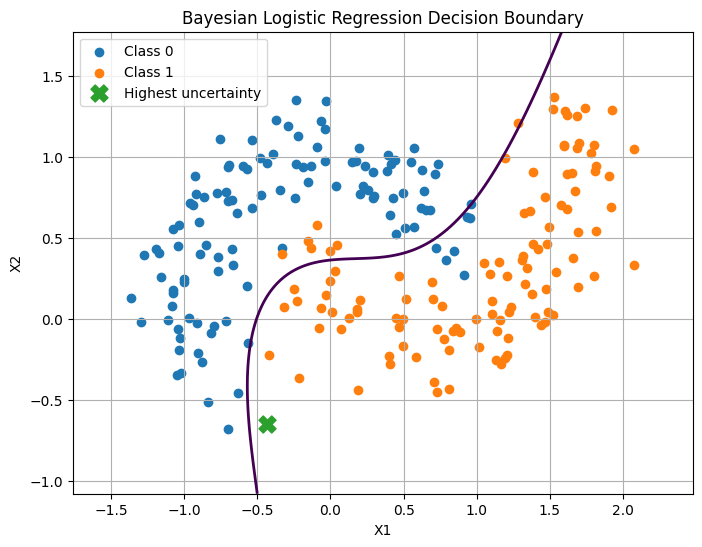

In [ ]:
# ============================================================
# CELL 15:
# BAYESIAN LOGISTIC REGRESSION DECISION BOUNDARY
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    label="Class 0"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Class 1"
)

# Bayesian decision boundary
plt.contour(
    xx,
    yy,
    bayes_probability_grid,
    levels=[0.5],
    linewidths=2
)

# Maximum meaningful uncertainty
plt.scatter(
    max_uncertainty_point[0],
    max_uncertainty_point[1],
    marker="X",
    s=150,
    label="Highest uncertainty"
)

plt.xlabel("X1")
plt.ylabel("X2")

plt.title(
    "Bayesian Logistic Regression Decision Boundary"
)

plt.legend()
plt.grid(True)

plt.show()

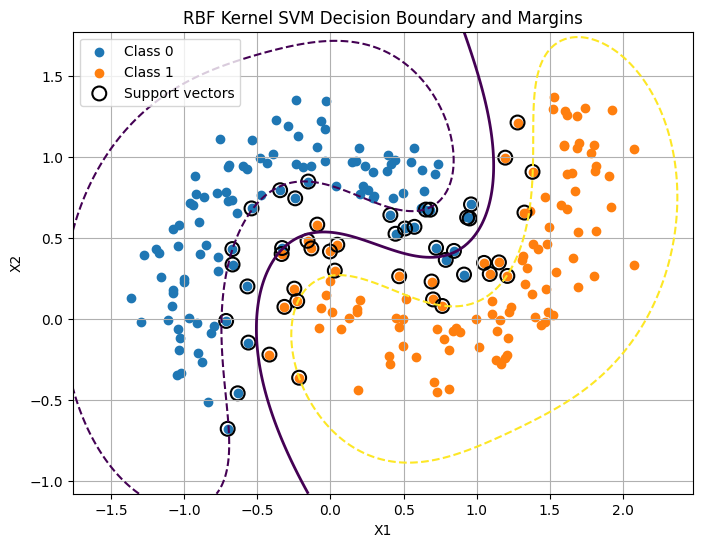

In [ ]:
# ============================================================
# CELL 16:
# RBF SVM DECISION BOUNDARY + MARGINS
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    label="Class 0"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Class 1"
)

# SVM decision boundary
plt.contour(
    xx,
    yy,
    svm_decision_grid,
    levels=[0],
    linewidths=2
)

# SVM margins
plt.contour(
    xx,
    yy,
    svm_decision_grid,
    levels=[-1, 1],
    linestyles="--",
    linewidths=1.5
)

# Support vectors
plt.scatter(
    X_train[
        support_vector_indices,
        0
    ],
    X_train[
        support_vector_indices,
        1
    ],
    facecolors="none",
    edgecolors="black",
    s=100,
    linewidths=1.5,
    label="Support vectors"
)

plt.xlabel("X1")
plt.ylabel("X2")

plt.title(
    "RBF Kernel SVM Decision Boundary and Margins"
)

plt.legend()
plt.grid(True)

plt.show()

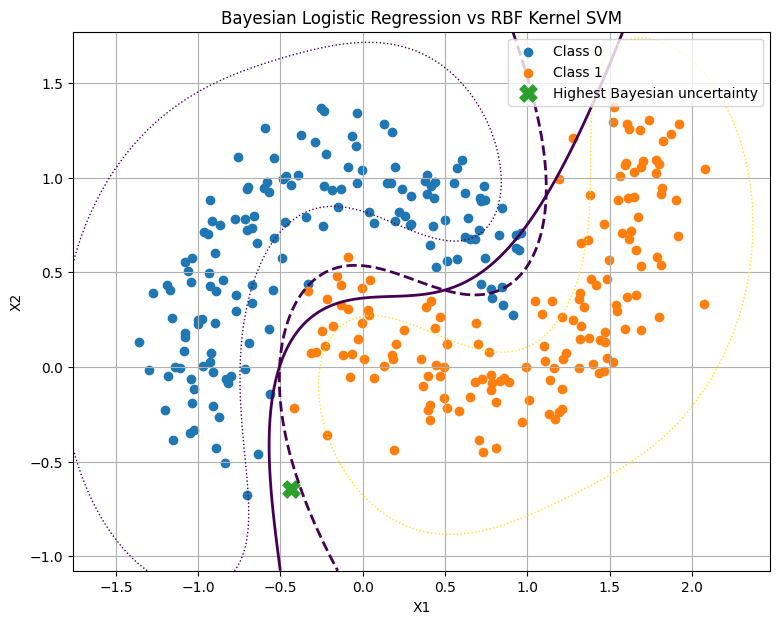

In [ ]:
# ============================================================
# CELL 17:
# BAYESIAN LOGISTIC REGRESSION vs RBF SVM
# ============================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1"
)

# ------------------------------------------------------------
# Bayesian boundary
# ------------------------------------------------------------

plt.contour(
    xx,
    yy,
    bayes_probability_grid,
    levels=[0.5],
    linewidths=2
)


# ------------------------------------------------------------
# SVM boundary
# ------------------------------------------------------------

plt.contour(
    xx,
    yy,
    svm_decision_grid,
    levels=[0],
    linewidths=2,
    linestyles="--"
)


# ------------------------------------------------------------
# SVM margins
# ------------------------------------------------------------

plt.contour(
    xx,
    yy,
    svm_decision_grid,
    levels=[-1, 1],
    linestyles=":",
    linewidths=1
)


# ------------------------------------------------------------
# Highest meaningful Bayesian uncertainty
# ------------------------------------------------------------

plt.scatter(
    max_uncertainty_point[0],
    max_uncertainty_point[1],
    marker="X",
    s=150,
    label="Highest Bayesian uncertainty"
)


plt.xlabel("X1")
plt.ylabel("X2")

plt.title(
    "Bayesian Logistic Regression vs RBF Kernel SVM"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# CELL 18:
# FINAL NUMERICAL SUMMARY
# ============================================================

print("=" * 70)
print("FINAL Q4 NUMERICAL SUMMARY")
print("=" * 70)

print("\nDATASET")
print("-" * 70)

print("Student seed:", SEED)
print("Number of samples:", len(X))
print("Noise:", round(noise, 4))
print("Rotation angle:", round(angle, 2), "degrees")


print("\nBAYESIAN LOGISTIC REGRESSION")
print("-" * 70)

print(
    "Basis-function dimension:",
    Phi_train.shape[1]
)

print(
    "Prior precision alpha:",
    alpha
)

print(
    "Newton-Raphson iterations:",
    iterations
)

print(
    "Training accuracy:",
    round(
        bayes_accuracy,
        4
    )
)


print("\nRBF KERNEL SVM")
print("-" * 70)

print("C:", C)

print("Gamma:", gamma)

print(
    "Support vectors:",
    n_support_vectors
)

print(
    "Bias:",
    round(
        b_svm,
        4
    )
)

print(
    "Training accuracy:",
    round(
        svm_accuracy,
        4
    )
)


print("\nUNCERTAINTY VS SVM MARGIN")
print("-" * 70)

print(
    "Highest meaningful uncertainty point:",
    np.round(
        max_uncertainty_point,
        4
    )
)

print(
    "Bayesian predictive uncertainty:",
    round(
        max_uncertainty_value,
        4
    )
)

print(
    "SVM decision value:",
    round(
        svm_value_at_point,
        4
    )
)

print(
    "Distance from SVM boundary:",
    round(
        abs(svm_value_at_point),
        4
    )
)

FINAL Q4 NUMERICAL SUMMARY

DATASET
----------------------------------------------------------------------
Student seed: 57
Number of samples: 300
Noise: 0.1884
Rotation angle: 26.39 degrees

BAYESIAN LOGISTIC REGRESSION
----------------------------------------------------------------------
Basis-function dimension: 10
Prior precision alpha: 1.0
Newton-Raphson iterations: 8
Training accuracy: 0.9422

RBF KERNEL SVM
----------------------------------------------------------------------
C: 1.0
Gamma: 1.0
Support vectors: 49
Bias: -0.0503
Training accuracy: 0.9867

UNCERTAINTY VS SVM MARGIN
----------------------------------------------------------------------
Highest meaningful uncertainty point: [-0.435  -0.6474]
Bayesian predictive uncertainty: 0.1795
SVM decision value: -0.1997
Distance from SVM boundary: 0.1997


Analysis:

A nonlinear two-class moon dataset was generated using seed 57, with student-specific noise 0.1884 and rotation of 26.39°.
Bayesian logistic regression used a 10-dimensional polynomial basis-function expansion instead of raw features.
Newton-Raphson optimization converged in 8 iterations to obtain the MAP estimate.
The Laplace approximation represented the posterior over weights as a Gaussian using the inverse Hessian as covariance.
The three test points produced probabilities of 0.2134, 0.7818 and 0.9932, with uncertainties of 0.0741, 0.0608 and 0.0148, respectively.
The RBF SVM was implemented using the RBF kernel and SMO optimization, producing 49 support vectors and 98.67% training accuracy.
The Bayesian and SVM boundaries differ because Bayesian logistic regression explicitly uses basis functions, while the kernel SVM implicitly maps data into a higher-dimensional feature space using the kernel trick.
The highest meaningful Bayesian uncertainty was 0.1795 at approximately [-0.435, -0.6474], where the SVM decision value was −0.1997.
Since −0.1997 lies between the SVM margins −1 and +1, this high-uncertainty point falls within the SVM margin region.
This shows that Bayesian uncertainty is concentrated around regions where the SVM also indicates classification ambiguity.